# Fase 1

Notebook com correlacao, regressao linear simples, graficos e respostas dos itens teoricos.

In [1]:
import math
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
class AnaliseLinear:
    def correlacao(self, x, y):
        n = len(x)
        soma_x = sum(x)
        soma_y = sum(y)
        soma_xy = sum(xi * yi for xi, yi in zip(x, y))
        soma_x2 = sum(xi * xi for xi in x)
        soma_y2 = sum(yi * yi for yi in y)

        numerador = n * soma_xy - soma_x * soma_y
        denominador = math.sqrt((n * soma_x2 - soma_x ** 2) * (n * soma_y2 - soma_y ** 2))

        if denominador == 0:
            raise ValueError('Nao e possivel calcular correlacao: denominador igual a zero')

        return numerador / denominador

    def regressao(self, x, y):
        n = len(x)
        soma_x = sum(x)
        soma_y = sum(y)
        soma_xy = sum(xi * yi for xi, yi in zip(x, y))
        soma_x2 = sum(xi * xi for xi in x)

        denominador = n * soma_x2 - soma_x ** 2
        if denominador == 0:
            raise ValueError('Nao e possivel calcular regressao: denominador igual a zero')

        beta1 = (n * soma_xy - soma_x * soma_y) / denominador
        beta0 = (soma_y - beta1 * soma_x) / n
        return beta0, beta1

In [3]:
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]

x2 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y2 = [9.14, 8.14, 8.47, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]

x3 = [8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 19]
y3 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 5.56, 7.91, 6.89, 12.50]

x4 = [10.0, 8.0, 13.0, 9.0, 11.0, 14.0, 6.0, 4.0, 12.0, 7.0, 5.0]
y4 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]

x5 = [10.0, 8.0, 9.0, 11.0, 14.0, 6.0, 4.0, 12.0, 7.0, 5.0]
y5 = [7.46, 6.77, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]

datasets = [
    ('Dataset 1', x1, y1),
    ('Dataset 2', x2, y2),
    ('Dataset 3', x3, y3),
    ('Dataset 4', x4, y4),
    ('Dataset 5', x5, y5),
]

In [4]:
analise = AnaliseLinear()

for nome, x, y in datasets:
    r = analise.correlacao(x, y)
    beta0, beta1 = analise.regressao(x, y)
    print(f'{nome}: r={r:.6f}, beta0={beta0:.6f}, beta1={beta1:.6f}')

Dataset 1: r=0.816421, beta0=3.000091, beta1=0.500091
Dataset 2: r=0.806117, beta0=3.064727, beta1=0.490182
Dataset 3: r=0.816521, beta0=3.001727, beta1=0.499909
Dataset 4: r=0.816287, beta0=3.002455, beta1=0.499727
Dataset 5: r=0.999997, beta0=4.005649, beta1=0.345390


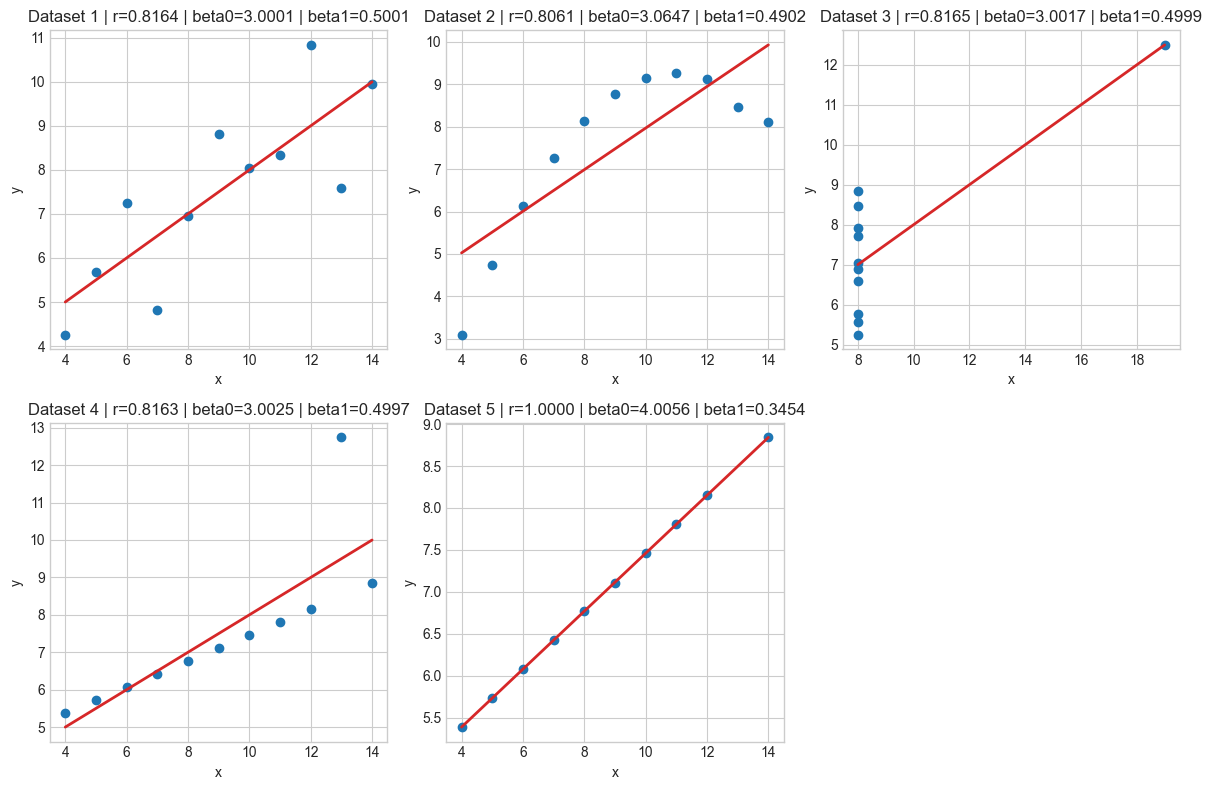

In [5]:
n_datasets = len(datasets)
n_cols = 3
n_rows = math.ceil(n_datasets / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows))
axes = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for i, (nome, x, y) in enumerate(datasets):
    beta0, beta1 = analise.regressao(x, y)
    r = analise.correlacao(x, y)
    x_linha = [min(x), max(x)]
    y_linha = [beta0 + beta1 * valor for valor in x_linha]

    axes[i].scatter(x, y, color='tab:blue')
    axes[i].plot(x_linha, y_linha, color='tab:red', linewidth=2)
    axes[i].set_title(f'{nome} | r={r:.4f} | beta0={beta0:.4f} | beta1={beta1:.4f}')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')

for j in range(n_datasets, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## Respostas dos itens 3 e 4

**3)** O dataset 2 e o que menos se ajusta bem a regressao linear simples, porque o grafico sugere um comportamento curvo, mais proximo de uma parabola.

**4)** No dataset 4 existe um outlier com valor de `y` bem acima dos demais. Esse ponto influencia diretamente a reta ajustada e deve ser investigado antes do ajuste final.